# Brecha digital y resultados Saber 11 en Colombia
### Proyecto final · Ciencia de Datos · Universidad EAN

**Integrantes:** [Integrante 1] · [Integrante 2] · [Integrante 3]
**Programa:** Ingeniería de Sistemas

---

**Pregunta que guía el proyecto**

> *¿Qué tanto se relaciona el acceso a internet y computador en el hogar con el puntaje global del examen Saber 11, y podemos usar esa información para predecir el desempeño de un estudiante?*

**¿Por qué este tema?** Como futuros ingenieros de sistemas, la conectividad y el acceso a tecnología son parte de nuestro campo de trabajo: diseñamos plataformas educativas, redes y sistemas de información para el sector público y privado. Entender si la **brecha digital** se traduce en una **brecha de aprendizaje** nos permite justificar con datos dónde invertir en infraestructura tecnológica y cómo diseñar herramientas que lleguen a quienes más las necesitan.

**Fuente de datos:** *Resultados únicos Saber 11* — ICFES, publicado en el portal de Datos Abiertos de Colombia ([datos.gov.co](https://www.datos.gov.co/resource/kgxf-xxbe)). Se trabaja con una **muestra sistemática** del periodo **2022-2** (estudiantes cuyo consecutivo termina en 317, 569 u 842), con 16 variables seleccionadas.

| Etapa | Módulo | Contenido |
|---|---|---|
| 1 | Fundamentos y herramientas | Selección, exploración y limpieza del dataset |
| 2 | Estadística descriptiva | Tendencia central, dispersión, outliers, comparación de grupos, hipótesis |
| 3 | Modelado y storytelling | Visualizaciones, regresión lineal, conclusiones y aplicación profesional |

In [1]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import os, warnings
warnings.filterwarnings("ignore")

# Estilo visual consistente para todo el proyecto
AZUL, NARANJA, GRIS, VERDE, ROJO = "#1f4e79", "#e07b39", "#9aa5b1", "#3a8f6b", "#c0392b"
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

os.makedirs("figuras", exist_ok=True)
def guardar(nombre):
    plt.savefig(f"figuras/{nombre}.png", dpi=150, bbox_inches="tight")

---
# ETAPA 1 · Fundamentos y herramientas de la Ciencia de Datos
**Objetivo:** seleccionar, explorar y preparar un conjunto de datos relevante.

## 1.1 Carga de datos
La función intenta primero leer el archivo del repositorio (`datos/`). Si no lo encuentra (por ejemplo, al abrir el cuaderno directamente en Google Colab), descarga **exactamente la misma muestra** desde la API pública de datos.gov.co.

In [2]:
ARCHIVO = "saber11_2022_muestra_raw.csv"
RUTAS = [f"datos/{ARCHIVO}", f"../datos/{ARCHIVO}", ARCHIVO]

COLUMNAS = ["periodo", "estu_consecutivo", "estu_genero", "estu_fechanacimiento",
            "cole_area_ubicacion", "cole_naturaleza", "cole_jornada", "cole_depto_ubicacion",
            "fami_estratovivienda", "fami_educacionmadre", "fami_tieneinternet",
            "fami_tienecomputador", "fami_personashogar",
            "punt_matematicas", "punt_lectura_critica", "punt_ingles", "punt_global"]

def descargar_desde_api():
    import requests
    filtro = ("periodo='20224' AND (estu_consecutivo like '%317' OR "
              "estu_consecutivo like '%569' OR estu_consecutivo like '%842')")
    params = {"$select": ",".join(COLUMNAS), "$where": filtro,
              "$order": "estu_consecutivo", "$limit": 50000}
    r = requests.get("https://www.datos.gov.co/resource/kgxf-xxbe.json", params=params, timeout=120)
    r.raise_for_status()
    return pd.DataFrame(r.json()).reindex(columns=COLUMNAS)

ruta = next((p for p in RUTAS if os.path.exists(p)), None)
if ruta:
    raw = pd.read_csv(ruta, dtype=str)
    print(f"Datos leídos desde: {ruta}")
else:
    raw = descargar_desde_api()
    raw.to_csv(ARCHIVO, index=False)
    print("Datos descargados desde la API de datos.gov.co")

print(f"Filas: {raw.shape[0]:,} | Columnas: {raw.shape[1]}")
raw.head()

Datos leídos desde: ../datos/saber11_2022_muestra_raw.csv
Filas: 3,170 | Columnas: 17


,periodo,estu_consecutivo,estu_genero,estu_fechanacimiento,cole_area_ubicacion,cole_naturaleza,cole_jornada,cole_depto_ubicacion,fami_estratovivienda,fami_educacionmadre,fami_tieneinternet,fami_tienecomputador,fami_personashogar,punt_matematicas,punt_lectura_critica,punt_ingles,punt_global
0,20224,SB11202240000317,F,02/12/2002,URBANO,OFICIAL,SABATINA,ANTIOQUIA,Sin Estrato,Secundaria (Bachillerato) completa,No,NaN,NaN,32,31,31,162
1,20224,SB11202240000317,F,02/12/2002,URBANO,OFICIAL,SABATINA,ANTIOQUIA,Sin Estrato,Secundaria (Bachillerato) completa,No,NaN,NaN,32,31,31,162
2,20224,SB11202240000569,F,NaN,RURAL,OFICIAL,MAÑANA,CAUCA,Estrato 1,Secundaria (Bachillerato) incompleta,No,No,3 a 4,43,32,32,199
3,20224,SB11202240000569,F,NaN,RURAL,OFICIAL,MAÑANA,CAUCA,Estrato 1,Secundaria (Bachillerato) incompleta,No,No,3 a 4,43,32,32,199
4,20224,SB11202240001569,M,17/10/2002,RURAL,OFICIAL,MAÑANA,NORTE SANTANDER,Estrato 2,Primaria incompleta,Si,No,5 a 6,40,53,41,232


## 1.2 Diccionario de variables

| Variable | Tipo | Descripción |
|---|---|---|
| `periodo` | Categórica | Periodo de aplicación (20224 = 2022, segundo semestre) |
| `estu_consecutivo` | Identificador | Código único del evaluado |
| `estu_genero` | Categórica nominal | F / M |
| `estu_fechanacimiento` | Fecha (texto) | Fecha de nacimiento dd/mm/aaaa |
| `cole_area_ubicacion` | Categórica nominal | Colegio urbano o rural |
| `cole_naturaleza` | Categórica nominal | Oficial (público) o no oficial (privado) |
| `cole_jornada` | Categórica nominal | Mañana, tarde, única, completa, noche, sabatina |
| `cole_depto_ubicacion` | Categórica nominal | Departamento del colegio |
| `fami_estratovivienda` | Categórica ordinal | Estrato socioeconómico 1–6 o "Sin estrato" |
| `fami_educacionmadre` | Categórica ordinal | Máximo nivel educativo de la madre |
| `fami_tieneinternet` | Binaria | ¿El hogar tiene internet? |
| `fami_tienecomputador` | Binaria | ¿El hogar tiene computador? |
| `fami_personashogar` | Categórica ordinal | Personas en el hogar (rangos) |
| `punt_matematicas`, `punt_lectura_critica`, `punt_ingles` | Numérica discreta | Puntaje por prueba (0–100) |
| `punt_global` | Numérica discreta | Puntaje global (0–500) — **variable objetivo** |

## 1.3 Exploración inicial

In [3]:
print("Tipos de datos al cargar:")
print(raw.dtypes.value_counts(), "\n")
raw.info()

Tipos de datos al cargar:
str    17
Name: count, dtype: int64 

<class 'pandas.DataFrame'>
RangeIndex: 3170 entries, 0 to 3169
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   periodo               3170 non-null   str  
 1   estu_consecutivo      3170 non-null   str  
 2   estu_genero           3170 non-null   str  
 3   estu_fechanacimiento  3168 non-null   str  
 4   cole_area_ubicacion   3170 non-null   str  
 5   cole_naturaleza       3170 non-null   str  
 6   cole_jornada          3170 non-null   str  
 7   cole_depto_ubicacion  3170 non-null   str  
 8   fami_estratovivienda  3000 non-null   str  
 9   fami_educacionmadre   3022 non-null   str  
 10  fami_tieneinternet    3022 non-null   str  
 11  fami_tienecomputador  3032 non-null   str  
 12  fami_personashogar    3034 non-null   str  
 13  punt_matematicas      3170 non-null   str  
 14  punt_lectura_critica  3170 non-null   str  
 15  pu

In [4]:
# Valores nulos por variable
nulos = pd.DataFrame({"nulos": raw.isna().sum(),
                      "% nulos": (raw.isna().mean() * 100).round(2)})
nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,% nulos
fami_estratovivienda,170,5.36
fami_educacionmadre,148,4.67
fami_tieneinternet,148,4.67
fami_tienecomputador,138,4.35
fami_personashogar,136,4.29
punt_ingles,10,0.32
estu_fechanacimiento,2,0.06


In [5]:
# Duplicados
dup_exactos = raw.duplicated().sum()
dup_id = raw["estu_consecutivo"].duplicated().sum()
print(f"Filas duplicadas exactas: {dup_exactos:,} ({dup_exactos/len(raw):.1%} del total)")
print(f"Consecutivos repetidos:   {dup_id:,}")
print(f"Estudiantes únicos:       {raw['estu_consecutivo'].nunique():,}")

Filas duplicadas exactas: 1,586 (50.0% del total)
Consecutivos repetidos:   1,586
Estudiantes únicos:       1,584


In [6]:
# Categorías de las variables de texto (para detectar codificaciones inadecuadas)
for col in ["cole_jornada", "fami_estratovivienda", "fami_educacionmadre", "fami_personashogar"]:
    print(f"--- {col} ---")
    print(raw[col].value_counts(dropna=False).to_string(), "\n")

--- cole_jornada ---
cole_jornada
MAÑANA      1218
UNICA        892
COMPLETA     488
TARDE        286
SABATINA     152
NOCHE        134 

--- fami_estratovivienda ---
fami_estratovivienda
Estrato 2      1048
Estrato 1       874
Estrato 3       690
Estrato 4       190
NaN             170
Sin Estrato     128
Estrato 5        48
Estrato 6        22 

--- fami_educacionmadre ---
fami_educacionmadre
Secundaria (Bachillerato) completa      862
Secundaria (Bachillerato) incompleta    424
Primaria incompleta                     386
Educación profesional completa          378
Técnica o tecnológica completa          324
Primaria completa                       276
NaN                                     148
Técnica o tecnológica incompleta        104
No sabe                                  90
Educación profesional incompleta         60
Ninguno                                  56
Postgrado                                56
No Aplica                                 6 

--- fami_personashogar ---
f

In [7]:
# Puntajes y fechas: ¿hay valores imposibles o sospechosos?
tmp = raw.copy()
for c in ["punt_matematicas", "punt_lectura_critica", "punt_ingles", "punt_global"]:
    tmp[c] = pd.to_numeric(tmp[c], errors="coerce")
fechas = pd.to_datetime(tmp["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")

print("Puntajes de inglés iguales a 0:", (tmp["punt_ingles"] == 0).sum())
print("Rango de fechas de nacimiento:", fechas.min().date(), "→", fechas.max().date())
print("Departamentos con tilde/sin tilde:", sorted(raw["cole_depto_ubicacion"].unique())[:8], "...")

Puntajes de inglés iguales a 0: 16
Rango de fechas de nacimiento: 1958-07-21 → 2008-07-17
Departamentos con tilde/sin tilde: ['AMAZONAS', 'ANTIOQUIA', 'ARAUCA', 'ATLANTICO', 'BOGOTÁ', 'BOLIVAR', 'BOYACA', 'CALDAS'] ...


## 1.4 Problemas detectados
| # | Problema | Evidencia | Decisión |
|---|---|---|---|
| 1 | **Duplicados** | 1.586 filas repetidas (50 % del archivo); cada estudiante aparece 2 o 4 veces en la fuente | Eliminar duplicados exactos → 1.584 estudiantes únicos |
| 2 | **Tipos incorrectos** | Todas las columnas llegan como texto, incluidos los puntajes | Convertir puntajes a numérico |
| 3 | **Valores imposibles/sospechosos** | 8 estudiantes con inglés = 0 pero puntajes normales en las demás pruebas | Tratar como dato faltante en inglés |
| 4 | **Fechas como texto y edades extremas** | Nacimientos entre 1958 y 2008; 2 sin fecha | Calcular edad y marcar atípicos (no se eliminan: son validantes adultos reales) |
| 5 | **Codificaciones que ocultan nulos** | "No sabe" y "No Aplica" en educación de la madre | Convertir a nulo |
| 6 | **Nulos en variables familiares** | Entre 4,3 % y 5,4 % en estrato, internet, computador, educación, personas | Conservar filas; imputar solo dentro del modelo |
| 7 | **Texto inconsistente** | Departamentos en mayúsculas y con/sin tilde (BOGOTÁ) | Normalizar y agrupar en regiones |
| 8 | **Categoría especial** | "Sin Estrato" no es un número | Conservarla como grupo propio |

## 1.5 Limpieza y transformación
Cada paso se documenta para que el proceso sea **reproducible**.

In [8]:
df = raw.copy()
registro = []   # bitácora de limpieza
def log(paso, antes, despues, detalle=""):
    registro.append({"Paso": paso, "Filas antes": antes, "Filas después": despues, "Detalle": detalle})

# 1) Eliminar duplicados exactos (la fuente publica algunos registros dos o más veces)
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log("Eliminar duplicados exactos", n0, len(df), f"{n0-len(df):,} filas repetidas")
assert df["estu_consecutivo"].is_unique

# 2) Tipos numéricos para los puntajes
for c in ["punt_matematicas", "punt_lectura_critica", "punt_ingles", "punt_global"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("Float64")
log("Convertir puntajes a numérico", len(df), len(df), "texto → número")

# 3) Inglés = 0 se trata como dato faltante (el resto de pruebas sí tiene puntaje,
#    lo que sugiere prueba no presentada/anulada y no un desempeño real de 0)
n_cero = int((df["punt_ingles"] == 0).sum())
df.loc[df["punt_ingles"] == 0, "punt_ingles"] = pd.NA
log("Inglés = 0 → nulo", len(df), len(df), f"{n_cero} registros")

# 4) Fecha de nacimiento → edad al momento del examen (ref. 28/08/2022, aplicación 2022-2)
df["fecha_nacimiento"] = pd.to_datetime(df["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
df["edad"] = ((pd.Timestamp("2022-08-28") - df["fecha_nacimiento"]).dt.days / 365.25).round(1)
log("Calcular edad", len(df), len(df), "fecha texto → datetime → años")

# 5) Respuestas que en realidad son 'no hay dato'
df["fami_educacionmadre"] = df["fami_educacionmadre"].replace({"No sabe": pd.NA, "No Aplica": pd.NA})
log("'No sabe' / 'No Aplica' → nulo", len(df), len(df), "educación de la madre")

# 6) Normalizar texto de departamentos (tildes y mayúsculas)
import unicodedata
def sin_tildes(s):
    return "".join(ch for ch in unicodedata.normalize("NFD", s) if unicodedata.category(ch) != "Mn")
df["departamento"] = df["cole_depto_ubicacion"].map(lambda s: sin_tildes(s).title())
log("Normalizar departamentos", len(df), len(df), "sin tildes, formato título")

print(pd.DataFrame(registro).to_string(index=False))

                          Paso  Filas antes  Filas después                       Detalle
   Eliminar duplicados exactos         3170           1584         1,586 filas repetidas
 Convertir puntajes a numérico         1584           1584                texto → número
             Inglés = 0 → nulo         1584           1584                   8 registros
                 Calcular edad         1584           1584 fecha texto → datetime → años
'No sabe' / 'No Aplica' → nulo         1584           1584         educación de la madre
      Normalizar departamentos         1584           1584    sin tildes, formato título


In [9]:
# 7) Variables derivadas (feature engineering)
df["internet"]    = df["fami_tieneinternet"].map({"Si": 1, "No": 0})
df["computador"]  = df["fami_tienecomputador"].map({"Si": 1, "No": 0})
df["acceso_digital"] = df["internet"] + df["computador"]        # 0, 1 o 2 recursos
df["acceso_digital_txt"] = df["acceso_digital"].map({0: "Ninguno", 1: "Solo uno", 2: "Internet + PC"})

df["colegio_privado"] = (df["cole_naturaleza"] == "NO OFICIAL").astype(int)
df["zona_urbana"]     = (df["cole_area_ubicacion"] == "URBANO").astype(int)
df["genero_m"]        = (df["estu_genero"] == "M").astype(int)
df["jornada_adultos"] = df["cole_jornada"].isin(["SABATINA", "NOCHE"]).astype(int)

# Estrato: número (1-6) y grupo; "Sin Estrato" se conserva como categoría propia
df["estrato_num"] = df["fami_estratovivienda"].str.extract(r"(\d)").astype(float)
df["estrato_grupo"] = np.select(
    [df["fami_estratovivienda"] == "Sin Estrato", df["estrato_num"] == 1, df["estrato_num"] == 2,
     df["estrato_num"] == 3, df["estrato_num"] >= 4],
    ["Sin estrato", "1", "2", "3", "4 a 6"], default=None)
df.loc[df["fami_estratovivienda"].isna(), "estrato_grupo"] = np.nan

# Educación de la madre: escala ordinal 0-9 y grupos legibles
orden_educ = {"Ninguno": 0, "Primaria incompleta": 1, "Primaria completa": 2,
              "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
              "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
              "Educación profesional incompleta": 7, "Educación profesional completa": 8, "Postgrado": 9}
df["educ_madre_nivel"] = df["fami_educacionmadre"].map(orden_educ)
df["educ_madre_grupo"] = pd.cut(df["educ_madre_nivel"], bins=[-1, 2, 4, 6, 9],
                                labels=["Primaria o menos", "Secundaria", "Técnica/Tecnológica", "Profesional/Posgrado"])

# Personas en el hogar: marca de clase de cada rango
df["personas_hogar"] = df["fami_personashogar"].map({"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5,
                                                     "7 a 8": 7.5, "9 o más": 9.0})
# Región natural
regiones = {
    # San Andrés se agrupa con el Caribe (solo 3 estudiantes en la muestra: un grupo propio sería inestable)
    "Caribe": ["Atlantico", "Bolivar", "Cesar", "Cordoba", "La Guajira", "Magdalena", "Sucre", "San Andres"],
    "Andina": ["Antioquia", "Boyaca", "Caldas", "Cundinamarca", "Bogota", "Huila", "Norte Santander",
               "Quindio", "Risaralda", "Santander", "Tolima"],
    "Pacífica": ["Choco", "Cauca", "Narino", "Valle"],
    "Orinoquía": ["Arauca", "Casanare", "Meta", "Vichada"],
    "Amazonía": ["Amazonas", "Caqueta", "Guaviare", "Putumayo", "Vaupes", "Guainia"]}
mapa_region = {d: r for r, ds in regiones.items() for d in ds}
df["region"] = df["departamento"].map(mapa_region)
assert df["region"].notna().all(), "Hay departamentos sin región asignada"

print("Distribución de acceso digital:")
print(df["acceso_digital_txt"].value_counts(dropna=False).to_string())

Distribución de acceso digital:
acceso_digital_txt
Internet + PC    748
Solo uno         378
Ninguno          344
NaN              114


In [10]:
# 8) Edad: identificar valores atípicos (validantes adultos) — se conservan pero se marcan
q1, q3 = df["edad"].quantile([.25, .75])
lim_sup = q3 + 1.5 * (q3 - q1)
df["edad_atipica"] = (df["edad"] > lim_sup).astype(int)
print(f"Límite superior IQR para edad: {lim_sup:.1f} años")
print(f"Estudiantes con edad atípica: {df['edad_atipica'].sum()} "
      f"({df['edad_atipica'].mean():.1%}); de ellos en jornada noche/sabatina: "
      f"{df.loc[df['edad_atipica']==1, 'jornada_adultos'].mean():.0%}")

Límite superior IQR para edad: 20.0 años
Estudiantes con edad atípica: 80 (5.1%); de ellos en jornada noche/sabatina: 64%


## 1.6 Dataset depurado

In [11]:
cols_finales = ["estu_consecutivo", "estu_genero", "edad", "edad_atipica", "region", "departamento",
                "cole_area_ubicacion", "cole_naturaleza", "cole_jornada", "jornada_adultos",
                "fami_estratovivienda", "estrato_num", "estrato_grupo",
                "fami_educacionmadre", "educ_madre_nivel", "educ_madre_grupo", "personas_hogar",
                "fami_tieneinternet", "fami_tienecomputador",
                "internet", "computador", "acceso_digital", "acceso_digital_txt",
                "colegio_privado", "zona_urbana", "genero_m",
                "punt_matematicas", "punt_lectura_critica", "punt_ingles", "punt_global"]
limpio = df[cols_finales].copy()

resumen = pd.DataFrame({
    "tipo": limpio.dtypes.astype(str),
    "no nulos": limpio.notna().sum(),
    "% nulos": (limpio.isna().mean() * 100).round(1),
    "valores únicos": limpio.nunique()})
print(f"Dataset final: {limpio.shape[0]:,} estudiantes × {limpio.shape[1]} variables")
resumen

Dataset final: 1,584 estudiantes × 30 variables


,tipo,no nulos,% nulos,valores únicos
estu_consecutivo,str,1584,0.00,1584
estu_genero,str,1584,0.00,2
edad,float64,1583,0.10,106
edad_atipica,int64,1584,0.00,2
region,str,1584,0.00,5
departamento,str,1584,0.00,32
cole_area_ubicacion,str,1584,0.00,2
cole_naturaleza,str,1584,0.00,2
cole_jornada,str,1584,0.00,6
jornada_adultos,int64,1584,0.00,2


In [12]:
destino = "../datos" if os.path.isdir("../datos") else ("datos" if os.path.isdir("datos") else ".")
limpio.to_csv(f"{destino}/saber11_2022_limpio.csv", index=False)
print(f"Guardado en {destino}/saber11_2022_limpio.csv")
limpio.head()

Guardado en ../datos/saber11_2022_limpio.csv


,estu_consecutivo,estu_genero,edad,edad_atipica,region,departamento,cole_area_ubicacion,cole_naturaleza,cole_jornada,jornada_adultos,fami_estratovivienda,estrato_num,estrato_grupo,fami_educacionmadre,educ_madre_nivel,educ_madre_grupo,personas_hogar,fami_tieneinternet,fami_tienecomputador,internet,computador,acceso_digital,acceso_digital_txt,colegio_privado,zona_urbana,genero_m,punt_matematicas,punt_lectura_critica,punt_ingles,punt_global
0,SB11202240000317,F,19.70,0,Andina,Antioquia,URBANO,OFICIAL,SABATINA,1,Sin Estrato,NaN,Sin estrato,Secundaria (Bachillerato) completa,4.00,Secundaria,NaN,No,NaN,0.00,NaN,NaN,NaN,0,1,0,32.00,31.00,31.00,162.00
1,SB11202240000569,F,NaN,0,Pacífica,Cauca,RURAL,OFICIAL,MAÑANA,0,Estrato 1,1.00,1,Secundaria (Bachillerato) incompleta,3.00,Secundaria,3.50,No,No,0.00,0.00,0.00,Ninguno,0,0,0,43.00,32.00,32.00,199.00
2,SB11202240001569,M,19.90,0,Andina,Norte Santander,RURAL,OFICIAL,MAÑANA,0,Estrato 2,2.00,2,Primaria incompleta,1.00,Primaria o menos,5.50,Si,No,1.00,0.00,1.00,Solo uno,0,0,1,40.00,53.00,41.00,232.00
3,SB11202240002317,M,32.10,1,Pacífica,Choco,URBANO,OFICIAL,MAÑANA,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,1,30.00,34.00,42.00,163.00
4,SB11202240003317,F,16.00,0,Andina,Antioquia,URBANO,NO OFICIAL,COMPLETA,0,Estrato 3,3.00,3,Educación profesional completa,8.00,Profesional/Posgrado,1.50,Si,Si,1.00,1.00,2.00,Internet + PC,1,1,0,61.00,68.00,76.00,314.00


**Resultado de la Etapa 1.** Pasamos de 3.170 filas crudas a **1.584 estudiantes únicos** con 30 variables limpias y documentadas. Además de corregir problemas, creamos variables nuevas que harán posible el análisis: `acceso_digital` (0, 1 o 2 recursos), `estrato_grupo`, `educ_madre_nivel`, `region`, `edad` y banderas binarias para el modelo. El archivo `datos/saber11_2022_limpio.csv` queda listo para las siguientes etapas.

---
# ETAPA 2 · Estadística descriptiva y preprocesamiento
**Objetivo:** aplicar medidas estadísticas descriptivas para comprender el comportamiento de los datos.

## 2.1 Medidas de tendencia central y dispersión

In [13]:
num = ["punt_global", "punt_matematicas", "punt_lectura_critica", "punt_ingles", "edad"]
def resumen_estadistico(s):
    s = s.dropna().astype(float)
    return pd.Series({
        "n": len(s), "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
        "mínimo": s.min(), "máximo": s.max(), "rango": s.max() - s.min(),
        "varianza": s.var(), "desv. estándar": s.std(),
        "coef. variación %": s.std() / s.mean() * 100,
        "Q1": s.quantile(.25), "Q3": s.quantile(.75), "IQR": s.quantile(.75) - s.quantile(.25),
        "asimetría": s.skew()})
tabla_desc = limpio[num].apply(resumen_estadistico).T
tabla_desc

,n,media,mediana,moda,mínimo,máximo,rango,varianza,desv. estándar,coef. variación %,Q1,Q3,IQR,asimetría
punt_global,"1,584.00",249.25,245.00,245.00,139.00,425.00,286.00,"2,566.71",50.66,20.33,210.00,287.00,77.00,0.29
punt_matematicas,"1,584.00",50.47,51.00,47.00,16.00,100.00,84.00,147.26,12.13,24.05,42.00,59.00,17.00,-0.02
punt_lectura_critica,"1,584.00",52.85,53.00,59.00,26.00,100.00,74.00,105.49,10.27,19.43,45.00,60.00,15.00,0.05
punt_ingles,"1,571.00",49.67,49.00,49.00,29.00,100.00,71.00,161.23,12.70,25.57,39.00,58.00,19.00,0.57
edad,"1,583.00",17.80,17.20,16.80,14.10,64.10,50.00,9.17,3.03,17.01,16.70,18.00,1.30,8.01


**Interpretación en lenguaje sencillo**

- **Puntaje global:** el estudiante típico obtiene unos **249 puntos de 500** (media 249,3; mediana 245; moda 245). Como la media es apenas mayor que la mediana, la distribución es casi simétrica con una cola leve hacia puntajes altos (asimetría 0,29).
- **Dispersión:** la desviación estándar es de **50,7 puntos** y la mitad central de los estudiantes está entre 210 y 287 (IQR = 77). Un coeficiente de variación del 20 % indica una variabilidad moderada: hay diferencias reales entre estudiantes que vale la pena explicar.
- **Pruebas individuales:** lectura crítica es la de mejor promedio (52,9) y la más homogénea (CV 19 %); **inglés y matemáticas son las más desiguales** (CV 26 % y 24 %).
- **Edad:** la mediana es 17,2 años, pero la asimetría de 8,0 delata una cola de adultos que presentan el examen como validantes (hasta 64 años).

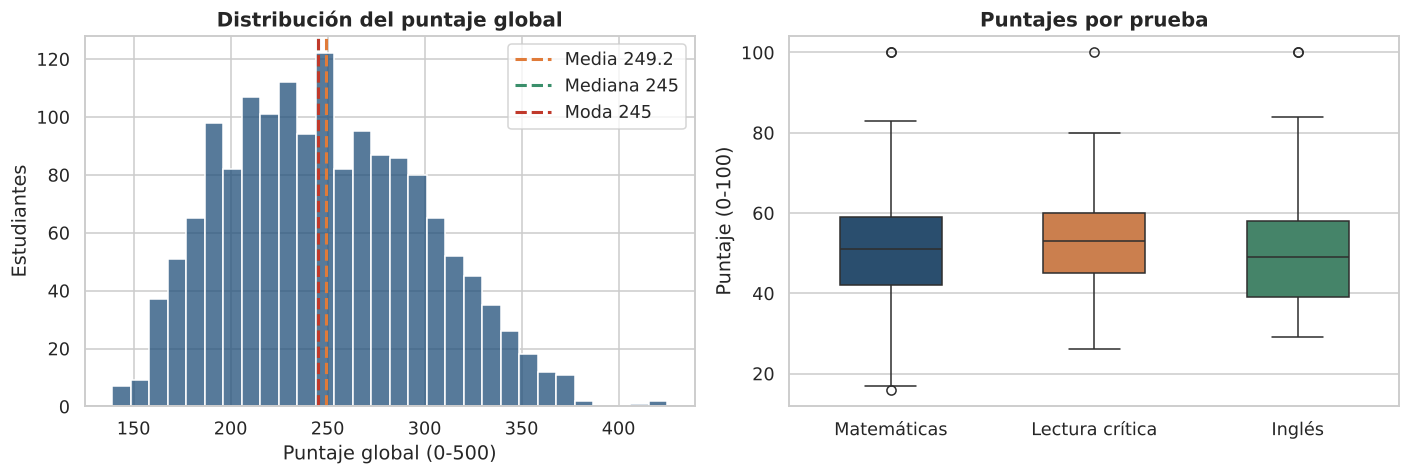

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
s = limpio["punt_global"].astype(float)
sns.histplot(s, bins=30, color=AZUL, ax=axes[0], edgecolor="white")
for v, c, lab in [(s.mean(), NARANJA, f"Media {s.mean():.1f}"),
                  (s.median(), VERDE, f"Mediana {s.median():.0f}"),
                  (s.mode().iloc[0], ROJO, f"Moda {s.mode().iloc[0]:.0f}")]:
    axes[0].axvline(v, color=c, ls="--", lw=2, label=lab)
axes[0].set(title="Distribución del puntaje global", xlabel="Puntaje global (0-500)", ylabel="Estudiantes")
axes[0].legend()

pruebas = limpio[["punt_matematicas", "punt_lectura_critica", "punt_ingles"]].astype(float)
pruebas.columns = ["Matemáticas", "Lectura crítica", "Inglés"]
sns.boxplot(data=pruebas, palette=[AZUL, NARANJA, VERDE], ax=axes[1], width=.5)
axes[1].set(title="Puntajes por prueba", ylabel="Puntaje (0-100)")
plt.tight_layout(); guardar("01_distribucion_puntajes"); plt.show()

## 2.2 Detección de valores atípicos (método IQR)
Un valor es atípico si está por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR.

In [15]:
filas = []
for c in num:
    s = limpio[c].dropna().astype(float)
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    filas.append({"variable": c, "límite inferior": li, "límite superior": ls,
                  "atípicos bajos": int((s < li).sum()), "atípicos altos": int((s > ls).sum()),
                  "% atípicos": ((s < li) | (s > ls)).mean() * 100})
outliers = pd.DataFrame(filas).set_index("variable")
outliers

,límite inferior,límite superior,atípicos bajos,atípicos altos,% atípicos
variable,,,,,
punt_global,94.50,402.50,0,3,0.19
punt_matematicas,16.50,84.50,1,2,0.19
punt_lectura_critica,22.50,82.50,0,1,0.06
punt_ingles,10.50,86.50,0,2,0.13
edad,14.75,19.95,2,80,5.18


In [16]:
lim = outliers.loc["punt_global", "límite superior"]
print("Estudiantes con puntaje global atípicamente alto:")
limpio.loc[limpio["punt_global"] > lim,
           ["punt_global", "punt_matematicas", "punt_lectura_critica", "punt_ingles",
            "cole_naturaleza", "fami_estratovivienda", "acceso_digital_txt"]].sort_values("punt_global", ascending=False)

Estudiantes con puntaje global atípicamente alto:


,punt_global,punt_matematicas,punt_lectura_critica,punt_ingles,cole_naturaleza,fami_estratovivienda,acceso_digital_txt
790,425.00,100.00,80.00,83.00,OFICIAL,Estrato 3,Solo uno
898,416.00,100.00,79.00,82.00,NO OFICIAL,Estrato 4,Internet + PC
983,412.00,79.00,75.00,78.00,OFICIAL,Estrato 2,Solo uno


**Interpretación.** En los puntajes casi no hay atípicos (menos del 0,2 %): los 3 estudiantes por encima de 402 puntos son **resultados excepcionales legítimos**, no errores, por lo que se conservan. Llama la atención que dos de ellos estudian en colegio oficial y no tienen acceso digital completo: el contexto influye, pero no determina. En la **edad sí hay atípicos** (80 estudiantes > 20 años, 5 %); el 64 % de ellos está en jornada nocturna o sabatina, lo que confirma que son validantes adultos. No se eliminan: se identifican con `edad_atipica` y `jornada_adultos` para que el modelo los tenga en cuenta.

## 2.3 Comparación de grupos
Comparamos el puntaje global según las variables de contexto. Las dos primeras (internet y computador) son el foco del proyecto.

In [17]:
def comparar(col, orden=None):
    g = limpio.groupby(col, observed=True)["punt_global"].agg(
        n="count", media="mean", mediana="median", desv="std").astype(float)
    if orden: g = g.reindex(orden)
    g["diferencia vs. menor"] = g["media"] - g["media"].min()
    return g.round(1)

comparaciones = {
    "Internet en el hogar": comparar("fami_tieneinternet"),
    "Computador en el hogar": comparar("fami_tienecomputador"),
    "Acceso digital": comparar("acceso_digital_txt", ["Ninguno", "Solo uno", "Internet + PC"]),
    "Estrato": comparar("estrato_grupo", ["Sin estrato", "1", "2", "3", "4 a 6"]),
    "Naturaleza del colegio": comparar("cole_naturaleza"),
    "Zona del colegio": comparar("cole_area_ubicacion"),
    "Educación de la madre": comparar("educ_madre_grupo"),
    "Género": comparar("estu_genero"),
}
for nombre, tabla in comparaciones.items():
    print(f"\n=== {nombre} ===")
    print(tabla.to_string())


=== Internet en el hogar ===
                          n  media  mediana  desv  diferencia vs. menor
fami_tieneinternet                                                     
No                   414.00 226.20   222.00 44.20                  0.00
Si                 1,096.00 259.10   258.00 50.00                 33.00

=== Computador en el hogar ===
                          n  media  mediana  desv  diferencia vs. menor
fami_tienecomputador                                                   
No                   690.00 233.40   228.00 45.40                  0.00
Si                   825.00 263.70   263.00 50.90                 30.30

=== Acceso digital ===
                        n  media  mediana  desv  diferencia vs. menor
acceso_digital_txt                                                   
Ninguno            344.00 223.40   220.00 41.50                  0.00
Solo uno           378.00 244.10   239.50 48.50                 20.70
Internet + PC      748.00 265.80   265.00 50.00           

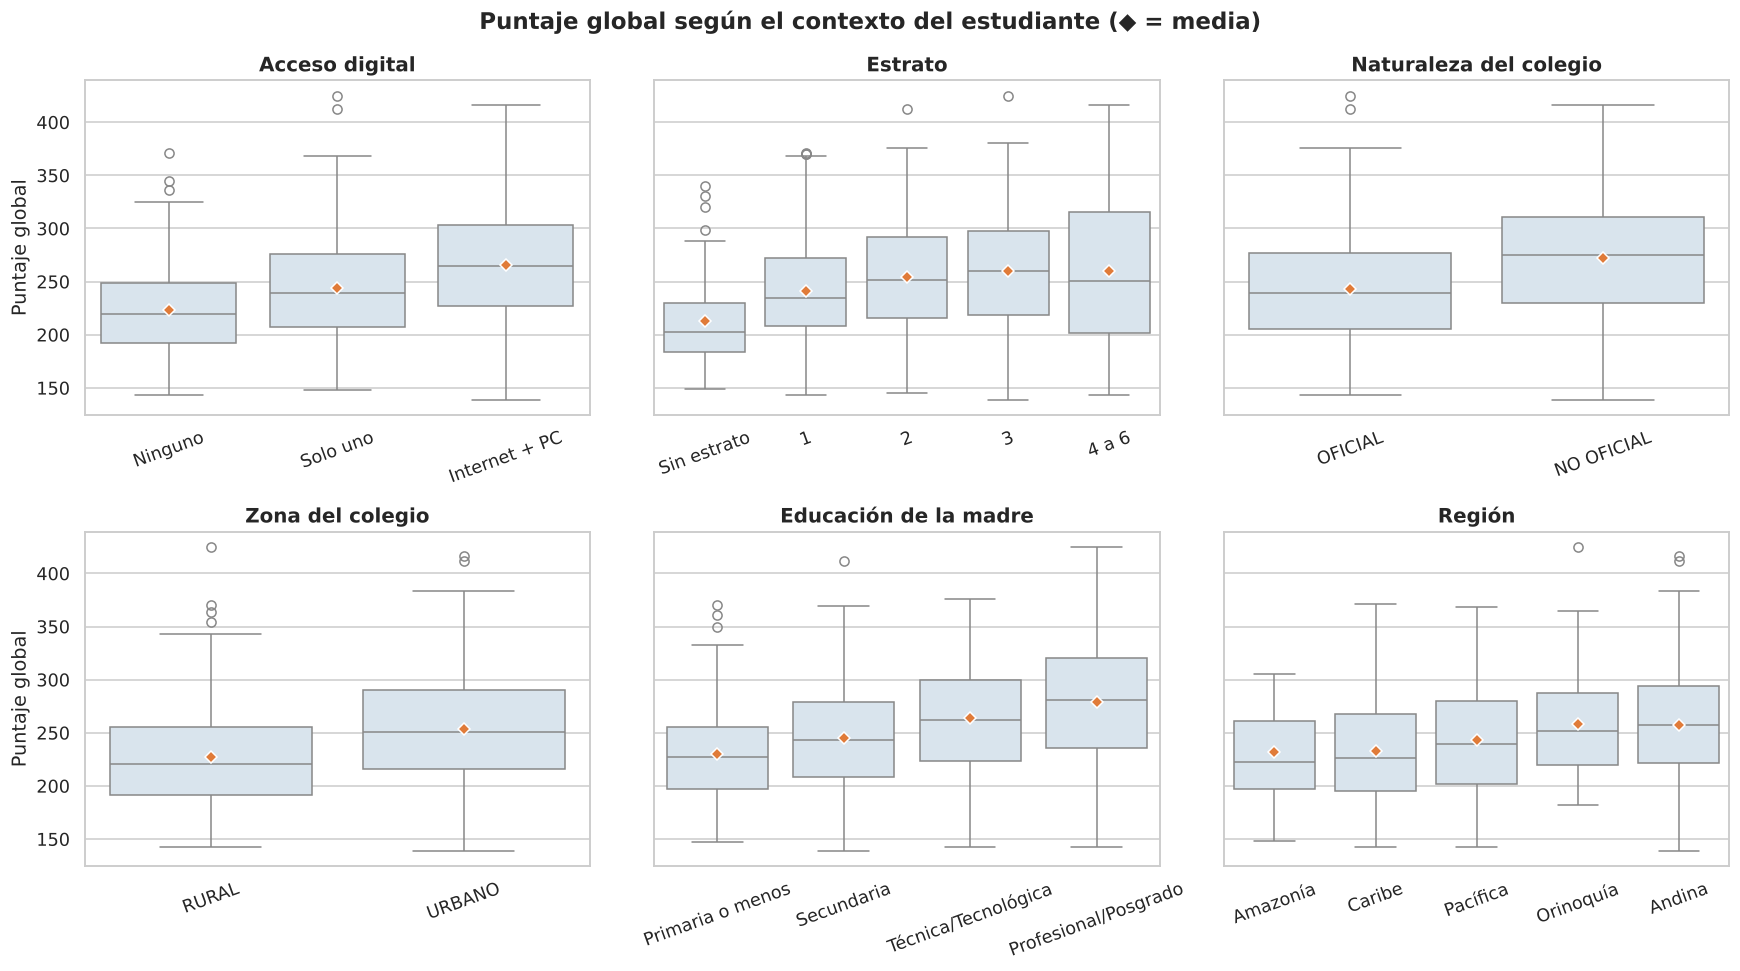

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
graficos = [("acceso_digital_txt", "Acceso digital", ["Ninguno", "Solo uno", "Internet + PC"]),
            ("estrato_grupo", "Estrato", ["Sin estrato", "1", "2", "3", "4 a 6"]),
            ("cole_naturaleza", "Naturaleza del colegio", ["OFICIAL", "NO OFICIAL"]),
            ("cole_area_ubicacion", "Zona del colegio", ["RURAL", "URBANO"]),
            ("educ_madre_grupo", "Educación de la madre", list(limpio["educ_madre_grupo"].cat.categories)),
            ("region", "Región", ["Amazonía", "Caribe", "Pacífica", "Orinoquía", "Andina"])]
for ax, (col, titulo, orden) in zip(axes.flat, graficos):
    datos = limpio.dropna(subset=[col]).astype({"punt_global": float})
    sns.boxplot(data=datos, x=col, y="punt_global", order=orden, ax=ax, color="#d6e4f0",
                showmeans=True, meanprops={"marker": "D", "markerfacecolor": NARANJA, "markeredgecolor": "white"})
    ax.set(title=titulo, xlabel="", ylabel="Puntaje global")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Puntaje global según el contexto del estudiante (◆ = media)", fontsize=15, fontweight="bold")
plt.tight_layout(); guardar("02_comparacion_grupos"); plt.show()

**Hallazgos principales**

- **Acceso digital:** quienes tienen internet **y** computador promedian **265,8 puntos**, frente a **223,4** de quienes no tienen ninguno: **42 puntos de diferencia**. Tener solo uno de los dos deja al estudiante en un punto intermedio (244,1). El patrón es escalonado: cada recurso suma.
- **Internet:** +33 puntos (259,1 vs 226,2). **Computador:** +30 puntos (263,7 vs 233,4).
- **Estrato:** el puntaje sube del grupo *sin estrato* (212,9) al estrato 3 (259,6), pero se estabiliza en estratos altos.
- **Colegio privado vs. oficial:** +29 puntos. **Urbano vs. rural:** +27 puntos.
- **Educación de la madre:** es el gradiente más claro; de *primaria o menos* (230) a *profesional/posgrado* (≈279).
- **Región:** Andina y Orinoquía (≈258) superan a Caribe y Amazonía (≈232).

**Hipótesis que surgen de la comparación**

- **H1:** el acceso digital en el hogar se asocia con un mayor puntaje global.
- **H2:** ese efecto no se explica únicamente por el estrato (debemos controlar otras variables).
- **H3:** la brecha digital es territorial: regiones con menos conectividad tienen menores puntajes.

## 2.4 Relaciones entre variables numéricas

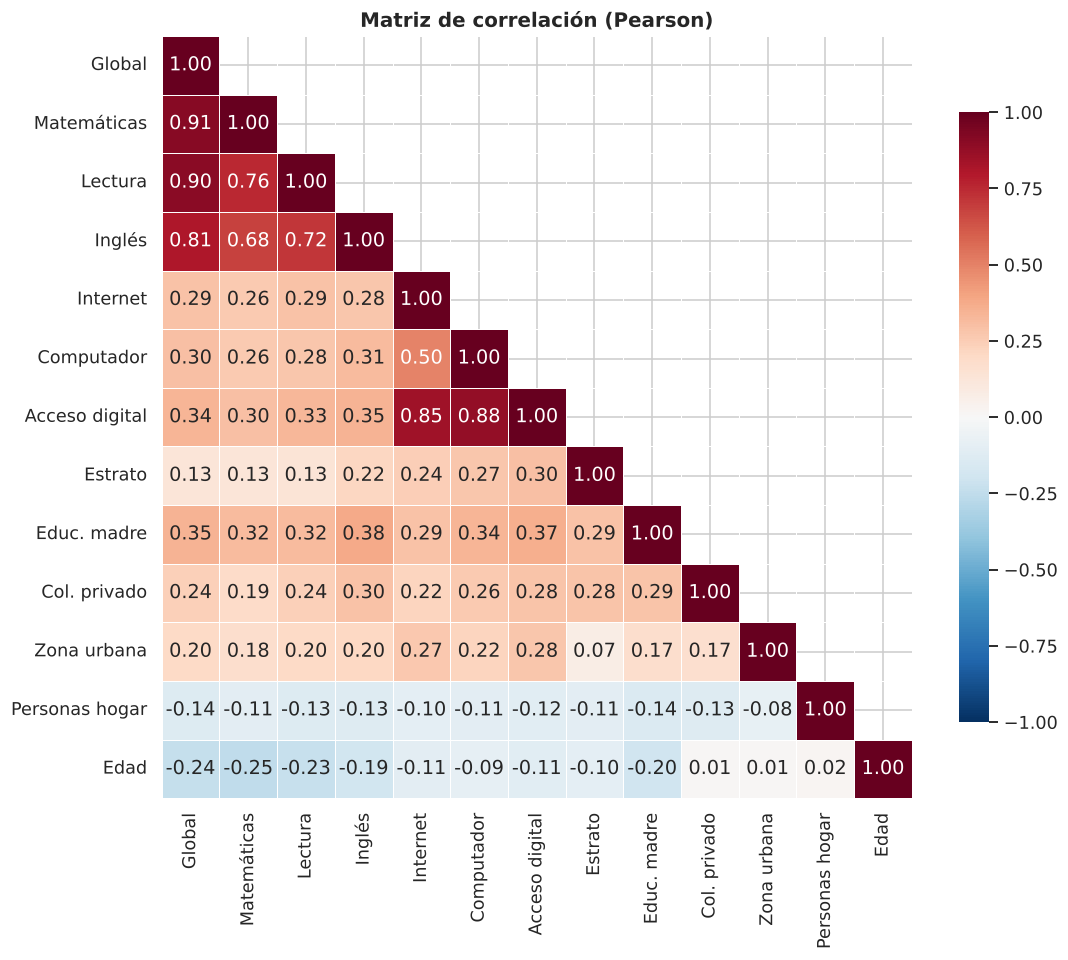

Correlación con el puntaje global (de mayor a menor):
Matemáticas       0.91
Lectura           0.90
Inglés            0.81
Educ. madre       0.35
Acceso digital    0.34
Computador        0.30
Internet          0.29
Col. privado      0.24
Zona urbana       0.20
Estrato           0.13
Personas hogar   -0.14
Edad             -0.24


In [19]:
vars_corr = ["punt_global", "punt_matematicas", "punt_lectura_critica", "punt_ingles",
             "internet", "computador", "acceso_digital", "estrato_num", "educ_madre_nivel",
             "colegio_privado", "zona_urbana", "personas_hogar", "edad"]
etiquetas = ["Global", "Matemáticas", "Lectura", "Inglés", "Internet", "Computador", "Acceso digital",
             "Estrato", "Educ. madre", "Col. privado", "Zona urbana", "Personas hogar", "Edad"]
corr = limpio[vars_corr].astype(float).corr()
corr.index = corr.columns = etiquetas
plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Matriz de correlación (Pearson)")
guardar("03_correlaciones"); plt.show()

print("Correlación con el puntaje global (de mayor a menor):")
print(corr["Global"].drop("Global").sort_values(ascending=False).round(3).to_string())

**Interpretación.** Las pruebas individuales correlacionan muy fuerte con el global (0,81–0,91) porque lo componen; por eso **no** se usarán como predictores. Entre las variables de contexto, las más asociadas al puntaje son la **educación de la madre (r = 0,35)** y el **acceso digital (r = 0,34)**, seguidas de computador (0,30) e internet (0,29). La edad tiene correlación negativa (−0,24): los validantes mayores obtienen puntajes más bajos. También se ve que internet, computador, estrato y educación de la madre están **correlacionados entre sí**: ese es el motivo para usar un modelo multivariado en la Etapa 3.

## 2.5 Pruebas de hipótesis
**H₀:** el puntaje global promedio es igual para estudiantes con y sin internet en el hogar.
**H₁:** los promedios son diferentes.

Usamos la prueba *t de Welch* (no asume varianzas iguales) y medimos el **tamaño del efecto** con la *d de Cohen*. Para el estrato (más de dos grupos) usamos ANOVA de una vía.

In [20]:
def cohen_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var() + (nb - 1) * b.var()) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp

resultados = []
for col, etiqueta in [("internet", "Internet"), ("computador", "Computador"),
                      ("colegio_privado", "Colegio privado"), ("zona_urbana", "Zona urbana")]:
    a = limpio.loc[limpio[col] == 1, "punt_global"].dropna().astype(float)
    b = limpio.loc[limpio[col] == 0, "punt_global"].dropna().astype(float)
    t, p = stats.ttest_ind(a, b, equal_var=False)
    resultados.append({"variable": etiqueta, "media con": a.mean(), "media sin": b.mean(),
                       "diferencia": a.mean() - b.mean(), "t": t, "p-valor": p, "d de Cohen": cohen_d(a, b)})
pruebas_t = pd.DataFrame(resultados).set_index("variable")
pd.options.display.float_format = lambda x: f"{x:,.4g}" if abs(x) < 0.001 else f"{x:,.2f}"
display(pruebas_t)

grupos = [g["punt_global"].astype(float).values for _, g in limpio.dropna(subset=["estrato_grupo"]).groupby("estrato_grupo")]
F, p_anova = stats.f_oneway(*grupos)
print(f"ANOVA por estrato: F = {F:.2f}, p-valor = {p_anova:.2e}")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

,media con,media sin,diferencia,t,p-valor,d de Cohen
variable,,,,,,
Internet,259.15,226.18,32.96,12.46,8.663e-33,0.68
Computador,263.66,233.40,30.26,12.23,7.522e-33,0.62
Colegio privado,271.86,242.86,29.00,9.32,3.206e-19,0.59
Zona urbana,254.01,227.28,26.73,8.50,3.218e-16,0.54


ANOVA por estrato: F = 18.04, p-valor = 1.75e-14


**Conclusión.** Para internet, el p-valor es prácticamente cero (8,7 × 10⁻³³), muy por debajo de 0,05: **rechazamos H₀**. La diferencia de 33 puntos no se debe al azar del muestreo. La **d de Cohen de 0,68** indica un efecto de tamaño **mediano-grande**, el mayor de las cuatro variables comparadas (computador 0,62; colegio privado 0,59; zona urbana 0,54). El ANOVA confirma también diferencias significativas entre estratos (F = 18,0; p < 0,001).

> ⚠️ Significativo no es lo mismo que causal: estas pruebas muestran **asociación**. El modelo de la Etapa 3 nos ayuda a separar el efecto del acceso digital del efecto de otras variables.

---
# ETAPA 3 · Modelado matemático y storytelling
**Objetivo:** comunicar hallazgos con visualizaciones efectivas y una narrativa basada en datos, y construir un modelo predictivo simple.

## 3.1 La historia en cuatro gráficos

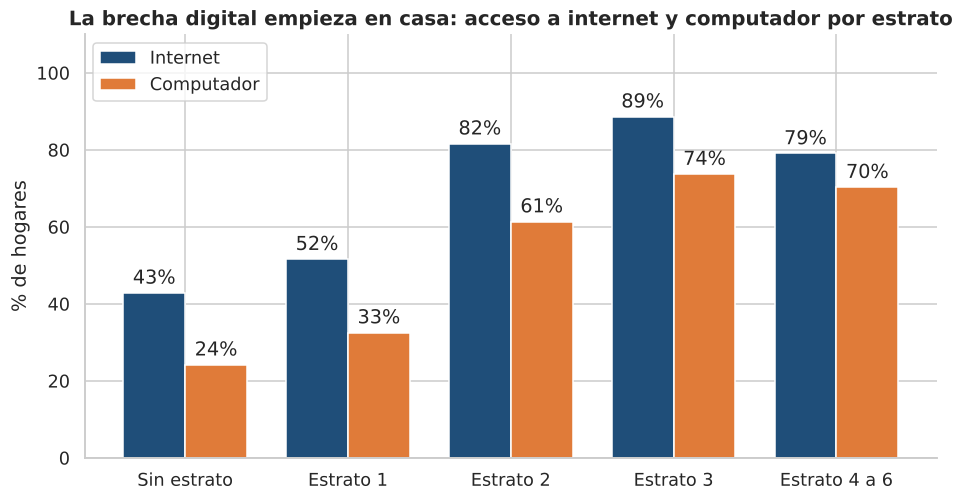

In [21]:
# Gráfico A: ¿quién tiene acceso? — % de hogares con internet y con computador por estrato
orden_e = ["Sin estrato", "1", "2", "3", "4 a 6"]
acc = (limpio.dropna(subset=["estrato_grupo"]).groupby("estrato_grupo")[["internet", "computador"]]
       .mean().reindex(orden_e) * 100)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(acc)); w = .38
b1 = ax.bar(x - w/2, acc["internet"], w, color=AZUL, label="Internet")
b2 = ax.bar(x + w/2, acc["computador"], w, color=NARANJA, label="Computador")
ax.bar_label(b1, fmt="%.0f%%", padding=3); ax.bar_label(b2, fmt="%.0f%%", padding=3)
ax.set(xticks=x, xticklabels=[f"Estrato {e}" if e[0].isdigit() else e for e in orden_e],
       ylim=(0, 110), ylabel="% de hogares",
       title="La brecha digital empieza en casa: acceso a internet y computador por estrato")
ax.legend(loc="upper left"); sns.despine()
guardar("04_acceso_por_estrato"); plt.show()

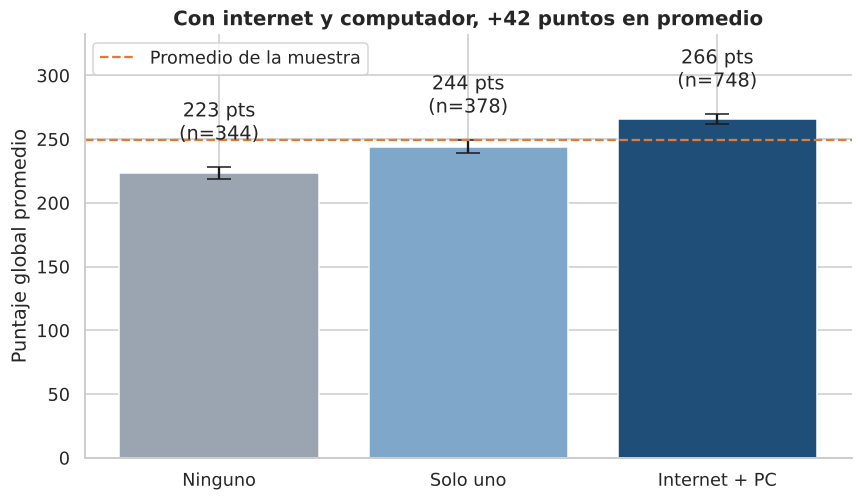

In [22]:
# Gráfico B: el efecto en el puntaje — media e intervalo de confianza del 95 % por nivel de acceso digital
orden_a = ["Ninguno", "Solo uno", "Internet + PC"]
g = limpio.dropna(subset=["acceso_digital_txt"]).groupby("acceso_digital_txt")["punt_global"].agg(["mean", "std", "count"]).reindex(orden_a).astype(float)
g["ic95"] = 1.96 * g["std"] / np.sqrt(g["count"])
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(orden_a, g["mean"], yerr=g["ic95"], capsize=8, color=[GRIS, "#7fa7c9", AZUL])
ax.bar_label(barras, labels=[f"{m:.0f} pts\n(n={n:.0f})" for m, n in zip(g["mean"], g["count"])], padding=14)
ax.axhline(limpio["punt_global"].astype(float).mean(), color=NARANJA, ls="--", lw=1.5, label="Promedio de la muestra")
ax.set(ylim=(0, g["mean"].max() * 1.25), ylabel="Puntaje global promedio",
       title=f"Con internet y computador, +{g['mean'].iloc[-1]-g['mean'].iloc[0]:.0f} puntos en promedio")
ax.legend(loc="upper left"); sns.despine()
guardar("05_puntaje_por_acceso"); plt.show()

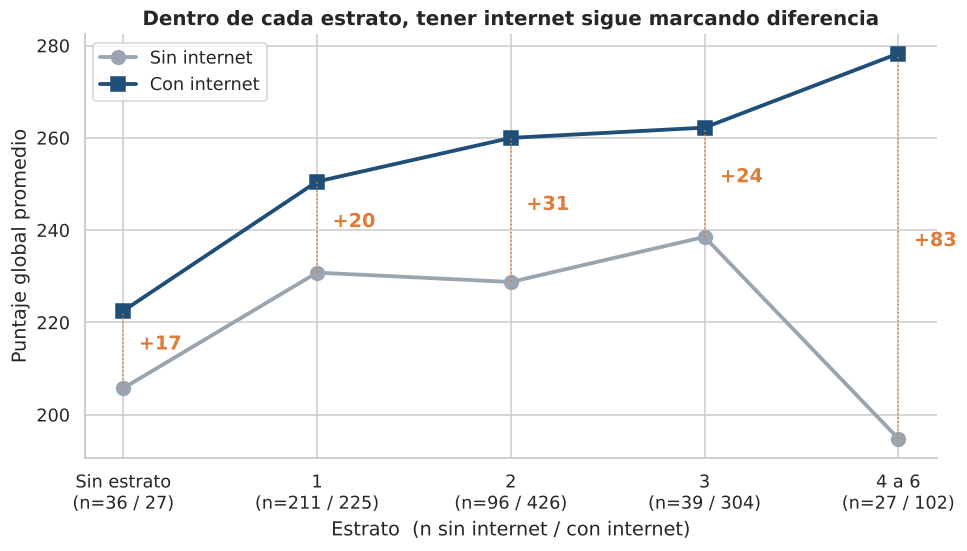

Internet       Con internet  Sin internet  n Con internet  n Sin internet
estrato_grupo                                                            
Sin estrato          222.50        205.80              27              36
1                    250.50        230.80             225             211
2                    260.00        228.80             426              96
3                    262.20        238.50             304              39
4 a 6                278.30        194.90             102              27


In [23]:
# Gráfico C: ¿es solo el estrato? — puntaje por estrato, separado por acceso a internet
datos = limpio.dropna(subset=["estrato_grupo", "fami_tieneinternet"]).copy()
datos["Internet"] = datos["fami_tieneinternet"].map({"Si": "Con internet", "No": "Sin internet"})
res = datos.groupby(["estrato_grupo", "Internet"])["punt_global"].mean().astype(float).unstack().reindex(orden_e)
fig, ax = plt.subplots(figsize=(10, 5))
for colname, color, mk in [("Sin internet", GRIS, "o"), ("Con internet", AZUL, "s")]:
    ax.plot(res.index, res[colname], marker=mk, ms=9, lw=2.5, color=color, label=colname)
for i, e in enumerate(res.index):
    ax.vlines(i, res.loc[e, "Sin internet"], res.loc[e, "Con internet"], color=NARANJA, lw=1, ls=":")
    ax.text(i + .08, res.loc[e].mean(), f"+{res.loc[e, 'Con internet'] - res.loc[e, 'Sin internet']:.0f}",
            color=NARANJA, fontweight="bold")
conteos = datos.groupby(["estrato_grupo", "Internet"]).size().unstack().reindex(orden_e)
ax.set_xticks(range(len(orden_e)))
ax.set_xticklabels([f"{e}\n(n={conteos.loc[e, 'Sin internet']} / {conteos.loc[e, 'Con internet']})" for e in orden_e])
ax.set(xlabel="Estrato  (n sin internet / con internet)", ylabel="Puntaje global promedio",
       title="Dentro de cada estrato, tener internet sigue marcando diferencia")
ax.legend(); sns.despine()
guardar("06_internet_dentro_de_estrato"); plt.show()
print(pd.concat([res.round(1), conteos.add_prefix("n ")], axis=1))

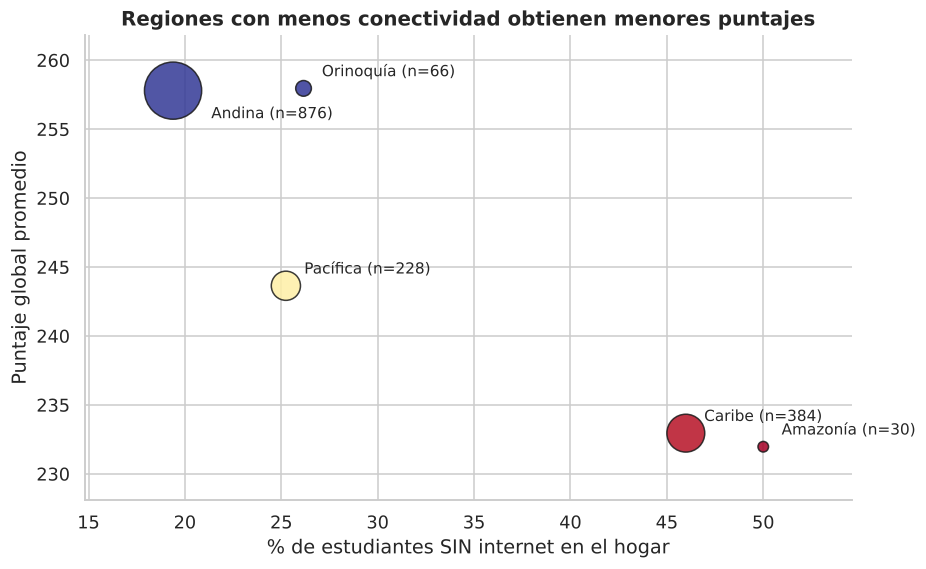

           sin_internet  puntaje      n
region                                 
Amazonía          50.00   232.00  30.00
Caribe            46.00   233.00 384.00
Pacífica          25.20   243.60 228.00
Andina            19.40   257.80 876.00
Orinoquía         26.20   258.00  66.00


In [24]:
# Gráfico D: el mapa de la brecha — % sin internet y puntaje promedio por región
reg = limpio.groupby("region").agg(sin_internet=("internet", lambda s: (1 - s.mean()) * 100),
                                   puntaje=("punt_global", "mean"), n=("punt_global", "size")).astype(float)
reg = reg.sort_values("puntaje")
fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(reg["sin_internet"], reg["puntaje"], s=reg["n"] * 1.6, c=reg["puntaje"], cmap="RdYlBu",
                edgecolor="k", alpha=.85)
desplaz = {"Andina": (25, -18), "Orinoquía": (12, 8)}
for r, fila in reg.iterrows():
    ax.annotate(f"{r} (n={fila['n']:.0f})", (fila["sin_internet"], fila["puntaje"]),
                xytext=desplaz.get(r, (12, 8)), textcoords="offset points", fontsize=10)
ax.margins(x=.15, y=.15)
ax.set(xlabel="% de estudiantes SIN internet en el hogar", ylabel="Puntaje global promedio",
       title="Regiones con menos conectividad obtienen menores puntajes")
sns.despine(); guardar("07_regiones"); plt.show()
print(reg.round(1))

**Lo que cuentan los gráficos**

- **A. La brecha empieza en casa:** el acceso a internet y computador crece con el estrato hasta el estrato 3. En estrato 1, aproximadamente la mitad de los hogares no tiene internet; en los grupos sin estrato el acceso es aún menor.
- **B. El acceso se refleja en el puntaje:** con internet y PC, el promedio es 42 puntos mayor que sin ninguno. Los intervalos de confianza no se superponen.
- **C. No es solo el estrato:** dentro de **cada** estrato, quienes tienen internet superan a quienes no lo tienen (entre +17 y +31 puntos en los estratos con grupos de tamaño suficiente). En estratos 4 a 6 la diferencia (+83) se basa en solo 27 estudiantes sin internet y debe leerse con precaución.
- **D. Es también territorial:** Caribe y Amazonía tienen cerca de la mitad de sus estudiantes sin internet y los menores puntajes promedio (~232–233); la región Andina, con 19 % sin internet, promedia 258.

## 3.2 Modelo 1 · Regresión lineal simple
Empezamos con el modelo más sencillo posible:

$$\text{puntaje global} = \beta_0 + \beta_1 \cdot \text{acceso digital} + \varepsilon$$

donde *acceso digital* vale 0 (ni internet ni computador), 1 (uno de los dos) o 2 (ambos).

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        223.2127      2.308     96.692      0.000     218.684     227.741
acceso_digital    21.2440      1.525     13.934      0.000      18.253      24.235

R² = 0.117   |   n = 1470


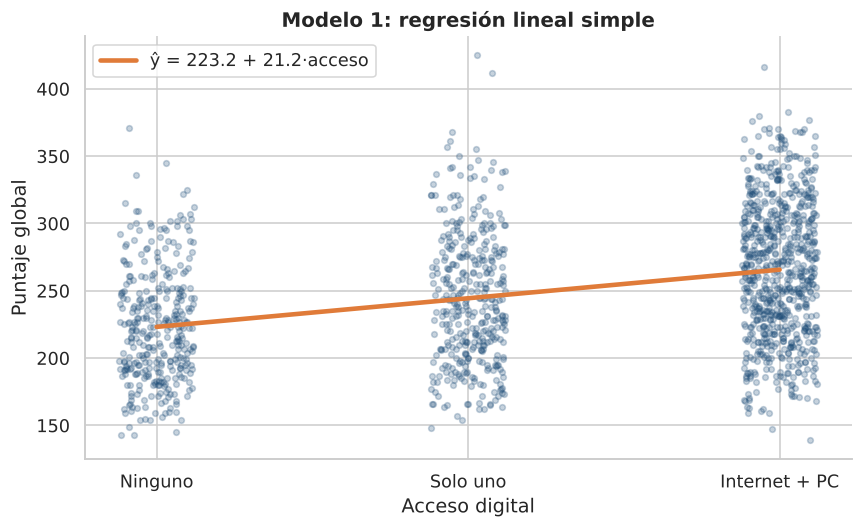

In [25]:
datos_m1 = limpio.dropna(subset=["acceso_digital"]).astype({"punt_global": float, "acceso_digital": float})
m1 = smf.ols("punt_global ~ acceso_digital", data=datos_m1).fit()
print(m1.summary().tables[1])
print(f"\nR² = {m1.rsquared:.3f}   |   n = {int(m1.nobs)}")

fig, ax = plt.subplots(figsize=(9, 5))
jitter = datos_m1["acceso_digital"] + np.random.default_rng(1).uniform(-.12, .12, len(datos_m1))
ax.scatter(jitter, datos_m1["punt_global"], alpha=.25, color=AZUL, s=14)
xs = np.array([0, 2])
ax.plot(xs, m1.params["Intercept"] + m1.params["acceso_digital"] * xs, color=NARANJA, lw=3,
        label=f"ŷ = {m1.params['Intercept']:.1f} + {m1.params['acceso_digital']:.1f}·acceso")
ax.set(xticks=[0, 1, 2], xticklabels=["Ninguno", "Solo uno", "Internet + PC"],
       xlabel="Acceso digital", ylabel="Puntaje global", title="Modelo 1: regresión lineal simple")
ax.legend(); sns.despine(); guardar("08_modelo_simple"); plt.show()

**Interpretación del modelo simple**

- **Intercepto (223,2):** puntaje esperado de un estudiante sin internet ni computador.
- **Pendiente (+21,2):** cada recurso digital adicional se asocia con **21 puntos más**, con un intervalo de confianza del 95 % entre 18,3 y 24,2. El efecto es estadísticamente significativo (p < 0,001).
- **R² = 0,117:** el acceso digital, por sí solo, explica cerca del **12 %** de la variación del puntaje. Es mucho para una sola variable binaria-ordinal, pero deja claro que el desempeño depende de muchos otros factores.

## 3.3 Modelo 2 · Regresión lineal múltiple (predictivo)
El modelo simple no controla otras variables. Ahora incluimos el contexto socioeconómico y del colegio para:

1. **Estimar el efecto del acceso digital "manteniendo todo lo demás constante"**.
2. **Predecir** el puntaje de un estudiante que el modelo no ha visto.

**Metodología:** partición 80 % entrenamiento / 20 % prueba, imputación de nulos dentro del *pipeline* (para no filtrar información del conjunto de prueba), validación cruzada de 5 particiones y comparación contra un modelo base que siempre predice el promedio.

> No usamos los puntajes de matemáticas, lectura o inglés como predictores: forman parte del puntaje global y el modelo sería trivial e inútil en la práctica (queremos predecir **antes** del examen).

In [26]:
binarias = ["internet", "computador", "colegio_privado", "zona_urbana", "genero_m", "jornada_adultos"]
numericas = ["educ_madre_nivel", "personas_hogar", "edad"]
categoricas = ["estrato_grupo", "region"]
X = limpio[binarias + numericas + categoricas].copy()
X[binarias + numericas] = X[binarias + numericas].astype(float)
X[categoricas] = X[categoricas].astype(object).where(X[categoricas].notna(), np.nan)
y = limpio["punt_global"].astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)

prepro = ColumnTransformer([
    ("bin", SimpleImputer(strategy="most_frequent"), binarias),
    ("num", SimpleImputer(strategy="median"), numericas),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(drop=["1", "Andina"], handle_unknown="ignore"))]), categoricas)])
modelo = Pipeline([("prep", prepro), ("reg", LinearRegression())])
modelo.fit(X_train, y_train)

base = DummyRegressor(strategy="mean").fit(X_train, y_train)
def metricas(nombre, y_real, y_pred):
    return {"modelo": nombre, "R²": r2_score(y_real, y_pred), "MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_pred))}
tabla_metricas = pd.DataFrame([
    metricas("Base (promedio)", y_test, base.predict(X_test)),
    metricas("Regresión múltiple · entrenamiento", y_train, modelo.predict(X_train)),
    metricas("Regresión múltiple · prueba", y_test, modelo.predict(X_test))]).set_index("modelo")
cv = cross_val_score(modelo, X, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
print(f"Validación cruzada (5 particiones): R² = {cv.mean():.3f} ± {cv.std():.3f}")
tabla_metricas

Validación cruzada (5 particiones): R² = 0.245 ± 0.021


,R²,MAE,RMSE
modelo,,,
Base (promedio),-0.00,42.63,50.86
Regresión múltiple · entrenamiento,0.27,35.14,43.23
Regresión múltiple · prueba,0.24,36.72,44.43


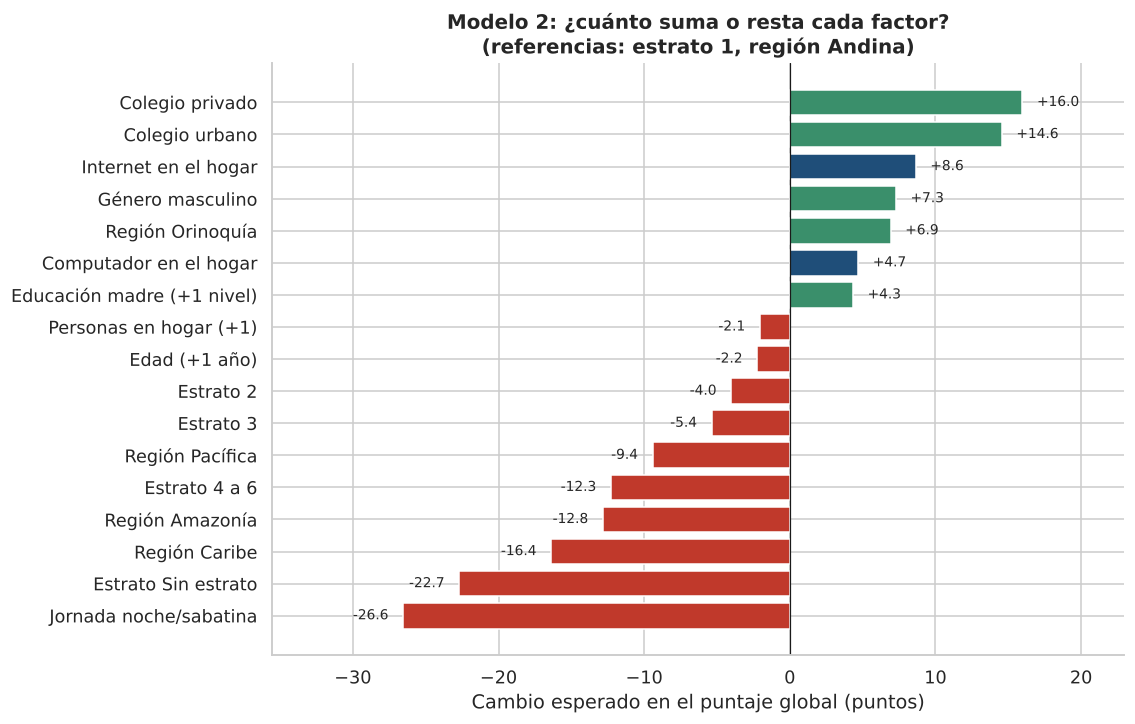

Intercepto: 265.3


In [27]:
# Coeficientes del modelo (en puntos del puntaje global)
nombres = (binarias + numericas +
           list(modelo.named_steps["prep"].named_transformers_["cat"].named_steps["ohe"].get_feature_names_out(categoricas)))
legibles = {"internet": "Internet en el hogar", "computador": "Computador en el hogar",
            "colegio_privado": "Colegio privado", "zona_urbana": "Colegio urbano", "genero_m": "Género masculino",
            "jornada_adultos": "Jornada noche/sabatina", "educ_madre_nivel": "Educación madre (+1 nivel)",
            "personas_hogar": "Personas en hogar (+1)", "edad": "Edad (+1 año)"}
coef = pd.Series(modelo.named_steps["reg"].coef_, index=nombres)
coef.index = [legibles.get(n, n.replace("estrato_grupo_", "Estrato ").replace("region_", "Región ")) for n in coef.index]
coef = coef.sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
colores = [AZUL if ("Internet" in n or "Computador" in n) else (VERDE if v > 0 else ROJO) for n, v in coef.items()]
ax.barh(coef.index, coef.values, color=colores)
ax.axvline(0, color="k", lw=.8)
for i, v in enumerate(coef.values):
    ax.text(v + (1 if v >= 0 else -1), i, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(coef.min() - 9, coef.max() + 7)
ax.set(xlabel="Cambio esperado en el puntaje global (puntos)",
       title="Modelo 2: ¿cuánto suma o resta cada factor?\n(referencias: estrato 1, región Andina)")
sns.despine(); guardar("09_coeficientes"); plt.show()
print(f"Intercepto: {modelo.named_steps['reg'].intercept_:.1f}")

In [28]:
# Inferencia: los mismos predictores con statsmodels para obtener intervalos de confianza y p-valores
datos_m2 = limpio.dropna(subset=binarias + numericas + categoricas).copy()
datos_m2[binarias + numericas + ["punt_global"]] = datos_m2[binarias + numericas + ["punt_global"]].astype(float)
datos_m2["estrato_grupo"] = datos_m2["estrato_grupo"].astype(str)
formula = ("punt_global ~ internet + computador + colegio_privado + zona_urbana + genero_m + jornada_adultos"
           " + educ_madre_nivel + personas_hogar + edad + C(estrato_grupo, Treatment('1')) + C(region, Treatment('Andina'))")
m2 = smf.ols(formula, data=datos_m2).fit()
inf = pd.DataFrame({"coef": m2.params, "IC 2,5%": m2.conf_int()[0], "IC 97,5%": m2.conf_int()[1], "p-valor": m2.pvalues})
print(f"n (casos completos) = {int(m2.nobs)} | R² = {m2.rsquared:.3f} | R² ajustado = {m2.rsquared_adj:.3f}")
inf.loc[["internet", "computador", "colegio_privado", "zona_urbana", "genero_m", "jornada_adultos",
         "educ_madre_nivel", "personas_hogar", "edad"]].round(3)

n (casos completos) = 1399 | R² = 0.269 | R² ajustado = 0.260


,coef,"IC 2,5%","IC 97,5%",p-valor
internet,9.96,3.73,16.18,0.00
computador,8.31,2.68,13.93,0.00
colegio_privado,14.60,8.52,20.68,0.00
zona_urbana,11.30,4.97,17.63,0.00
genero_m,6.45,1.82,11.08,0.01
jornada_adultos,-24.94,-34.28,-15.60,0.00
educ_madre_nivel,4.65,3.51,5.80,0.00
personas_hogar,-1.43,-2.87,0.01,0.05
edad,-2.16,-3.10,-1.22,0.00


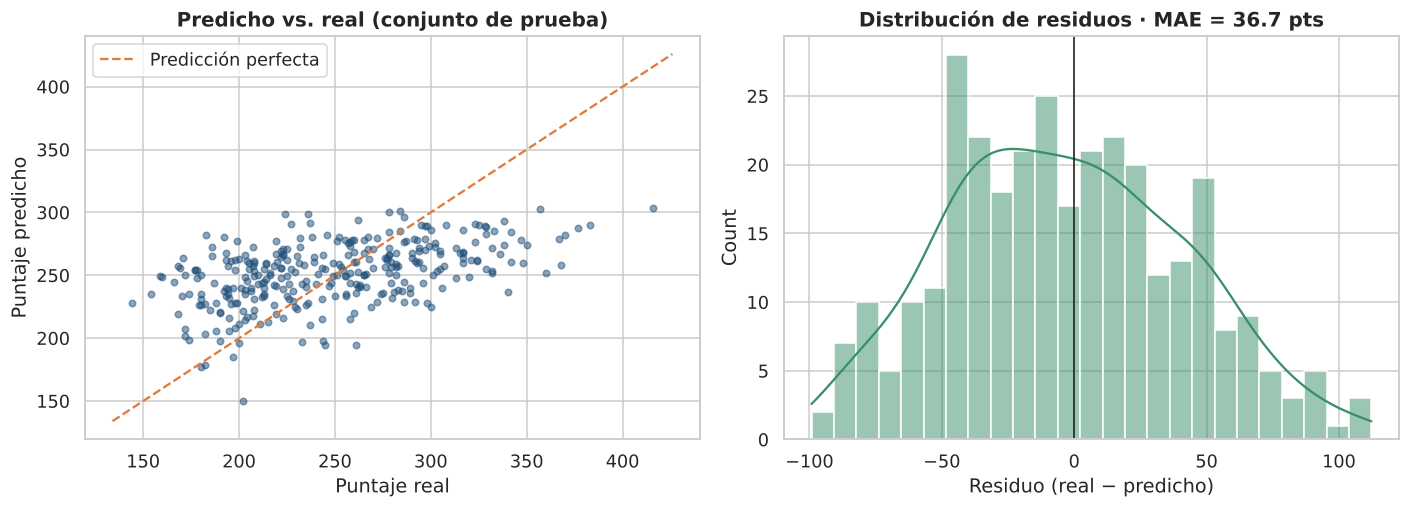

In [29]:
# Diagnóstico: predicho vs. real y residuos
pred = modelo.predict(X_test); resid = y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(y_test, pred, alpha=.5, color=AZUL, s=18)
lims = [min(y_test.min(), pred.min()) - 10, max(y_test.max(), pred.max()) + 10]
axes[0].plot(lims, lims, color=NARANJA, ls="--", label="Predicción perfecta")
axes[0].set(xlabel="Puntaje real", ylabel="Puntaje predicho", title="Predicho vs. real (conjunto de prueba)")
axes[0].legend()
sns.histplot(resid, bins=25, kde=True, color=VERDE, ax=axes[1])
axes[1].axvline(0, color="k", lw=1)
axes[1].set(xlabel="Residuo (real − predicho)", title=f"Distribución de residuos · MAE = {np.abs(resid).mean():.1f} pts")
plt.tight_layout(); guardar("10_diagnostico_modelo"); plt.show()

In [30]:
# Ejemplo de uso: dos estudiantes idénticos excepto por el acceso digital
perfil = pd.DataFrame([
    {"internet": 0, "computador": 0, "colegio_privado": 0, "zona_urbana": 0, "genero_m": 0, "jornada_adultos": 0,
     "educ_madre_nivel": 4, "personas_hogar": 3.5, "edad": 17, "estrato_grupo": "1", "region": "Caribe"},
    {"internet": 1, "computador": 1, "colegio_privado": 0, "zona_urbana": 0, "genero_m": 0, "jornada_adultos": 0,
     "educ_madre_nivel": 4, "personas_hogar": 3.5, "edad": 17, "estrato_grupo": "1", "region": "Caribe"}],
    index=["Sin internet ni PC", "Con internet y PC"])
perfil["puntaje predicho"] = modelo.predict(perfil[X.columns]).round(1)
perfil[["internet", "computador", "estrato_grupo", "region", "puntaje predicho"]]

,internet,computador,estrato_grupo,region,puntaje predicho
Sin internet ni PC,0,0,1,Caribe,220.90
Con internet y PC,1,1,1,Caribe,234.20


**Interpretación del modelo múltiple**

**Desempeño predictivo**

- En datos que el modelo **nunca vio** (prueba), alcanza un **R² de 0,24** y se equivoca en promedio **36,7 puntos** (MAE), frente a 42,6 del modelo base: una mejora del **14 %** en el error.
- La validación cruzada (R² = 0,245 ± 0,021) y la poca diferencia entre entrenamiento (0,27) y prueba (0,24) indican que el modelo **no está sobreajustado** y es estable.
- Un R² de 0,24 es razonable en ciencias sociales: las variables de contexto explican una cuarta parte; el resto depende de factores no observados (motivación, calidad docente, preparación, etc.).

**¿Qué dice sobre el acceso digital?** *(manteniendo constantes las demás variables)*

- **Internet en el hogar: +10 puntos** (IC 95 %: 3,7 a 16,2; p = 0,002).
- **Computador en el hogar: +8 puntos** (IC 95 %: 2,7 a 13,9; p = 0,004).
- Juntos suman ~18 puntos. El efecto es menor que la diferencia bruta de 42 puntos, porque parte de esa brecha se explica por educación de la madre, tipo de colegio y zona. Aun así, **sigue siendo significativo después de controlar por el contexto socioeconómico**, lo que respalda la hipótesis H2.

**Otros resultados relevantes**

- La **educación de la madre** suma ~4,7 puntos por cada nivel educativo adicional: es el factor familiar más fuerte.
- **Colegio privado (+14,6)** y **urbano (+11,3)** también aportan; la **jornada nocturna o sabatina** resta ~25 puntos.
- **El estrato pierde su efecto positivo** una vez se controla por las demás variables: lo que el estrato "compra" (internet, PC, colegio, educación de los padres) es lo que realmente se relaciona con el puntaje.
- La región Caribe obtiene ~16 puntos menos que la Andina, aun con características similares.

**Ejemplo práctico:** para dos estudiantes idénticos (estrato 1, colegio oficial rural del Caribe, madre bachiller), el modelo predice **221 puntos sin internet ni PC** y **234 puntos con ambos**: unos 13 puntos de diferencia atribuibles al acceso digital.

> *Nota: los coeficientes de scikit-learn (entrenado con el 80 % de los datos e imputación) y de statsmodels (casos completos) difieren ligeramente, pero apuntan en la misma dirección.*

## 3.4 Storytelling: lo que nos cuentan los datos
**1. El punto de partida.** En 2022, cerca de **3 de cada 10** estudiantes de nuestra muestra presentaron el Saber 11 sin internet en casa, y casi la mitad sin computador.

**2. El conflicto.** Esos estudiantes obtienen en promedio **42 puntos menos** que quienes tienen ambos recursos. La brecha no se reparte por igual: se concentra en los estratos bajos, en los colegios rurales y en regiones como el **Caribe y la Amazonía**, donde la mitad de los estudiantes no tiene conexión.

**3. La pregunta incómoda.** *¿No será que todo se explica por el estrato?* Los datos dicen que no del todo: **dentro de cada estrato** quienes tienen internet rinden más, y en el modelo multivariado el acceso digital sigue sumando **~18 puntos** aun comparando estudiantes con el mismo estrato, colegio, zona, región y educación de la madre.

**4. El desenlace.** El acceso digital no es el único factor (la educación de la madre y el tipo de colegio pesan tanto o más), pero es uno de los pocos que **se pueden intervenir con tecnología e inversión pública** en el corto plazo. Ahí es donde un ingeniero de sistemas puede generar impacto.

| Mensaje clave | Dato que lo respalda |
|---|---|
| La brecha digital es real | 28 % sin internet, 46 % sin computador |
| Se traduce en brecha de aprendizaje | +42 puntos con internet + PC (d de Cohen 0,68 solo internet) |
| No es solo el estrato | +10 (internet) y +8 (PC) controlando el contexto |
| Tiene geografía | Caribe y Amazonía: ~50 % sin internet, ~232 puntos |

## 3.5 Aplicación profesional · Ingeniería de Sistemas
**Propuesta: Sistema de alerta temprana y priorización de conectividad educativa**

Como ingenieros de sistemas proponemos convertir este análisis en un **producto de datos** para una Secretaría de Educación, el Ministerio TIC o una fundación educativa:

1. **Ingesta automática (ETL):** un *pipeline* en Python que consulta periódicamente la API de datos.gov.co, aplica la misma limpieza de la Etapa 1 y guarda los datos en una base de datos (por ejemplo, PostgreSQL).
2. **Modelo de riesgo:** el modelo de regresión se re-entrena con cada periodo y estima el puntaje esperado de cada colegio o municipio a partir de su contexto, **antes** del examen.
3. **Tablero de decisión:** un dashboard (Power BI, Looker Studio o Streamlit) muestra en un mapa los municipios con más estudiantes sin internet/PC y menor puntaje esperado, para priorizar dónde instalar zonas wifi, entregar equipos o abrir aulas digitales.
4. **Medición de impacto:** después de una intervención se comparan los resultados reales con los esperados por el modelo para saber si la inversión funcionó.

**¿Dónde más aplicaríamos estas herramientas?**

- En una empresa de **telecomunicaciones**, para identificar zonas con demanda insatisfecha de conectividad.
- En una **plataforma EdTech**, para diseñar contenidos que funcionen sin conexión permanente (modo *offline*) para los estudiantes con menos acceso.
- En general, cada vez que haya que **limpiar datos públicos, encontrar patrones, probar hipótesis y comunicar resultados** a personas que toman decisiones.

## 3.6 Limitaciones y próximos pasos
- **Asociación, no causalidad:** los datos son observacionales; el acceso digital puede estar reflejando otros factores no medidos (ingreso exacto, hábitos de estudio).
- **Muestra:** 1.584 estudiantes de un solo periodo (2022-2), seleccionados sistemáticamente por el consecutivo. Algunas regiones (Amazonía, Orinoquía) tienen pocos casos.
- **Variables autoreportadas:** internet y computador vienen del formulario del estudiante; no sabemos la calidad de la conexión ni el uso real.
- **Poder explicativo moderado:** el modelo explica ~25 % de la variación.

**Próximos pasos:** ampliar a todos los periodos 2019–2024 para ver la evolución (incluida la pandemia), probar modelos no lineales (árboles, *random forest*) y cruzar con datos de cobertura de internet fijo del MinTIC por municipio.

---
### Referencias
- ICFES. *Resultados únicos Saber 11*. Portal de Datos Abiertos de Colombia, conjunto `kgxf-xxbe`. https://www.datos.gov.co/resource/kgxf-xxbe
- Documentación de pandas, scikit-learn, statsmodels, seaborn y SciPy.